# L6 / E23 — Qwen2.5-3B-Instruct · Context-aware question interpretation (zero-shot)

**Exploratory, label-informed follow-up to E20.** Same 14,639 redacted airline tweets, Qwen model, greedy decoding, evaluation protocol and visualizations. The only modelling change is a question-specific addition to E20's sentiment prompt. Separate E23 checkpoint and output directory; no labelled examples or fine-tuning.


**Hypothesis:** A question mark is not a sentiment label. An information-seeking question can be neutral; a rhetorical question can express frustration or praise. Explicitly directing Qwen to distinguish questions by their **full meaning and intent** may improve neutral classification without losing genuine complaints.

**Design:** Use the complete E20 prompt plus one additional question-interpretation rule. Preserve punctuation and the original redacted tweet text; do **not** delete question marks. No engineered features. No human labels are read before predictions are frozen. This is exploratory prompt development on a corpus whose labels have already been examined, not independent validation.


In [1]:
# 1 — Install only the missing Qwen dependencies (Colab)
# Keep Colab-provided NumPy, pandas, SciPy, scikit-learn and PyTorch.
# Do not force-reinstall or upgrade the core numerical stack.
%pip install -q "transformers>=4.45,<5" accelerate safetensors

#continue to run when error appear:


#ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
#gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
#gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
#diffusers 0.42.0 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.0 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


**Run sequentially.** Keep the source CSV text-only. The model and tokenizer load in Cell #4. You can restart a disconnected runtime and resume the saved prediction checkpoint, provided the model, prompt and input text remain unchanged. The labelled dataset is not opened until Cell #9.

In [3]:
# 2 — Input and output locations (no labelled CSV here)
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')
INPUT_CSV = Path('/content/drive/MyDrive/MSI5001 project/EDA/Tweets-redacted.csv')
OUTPUT_DIR = Path('/content/drive/MyDrive/MSI5001 project/EDA/L6-externaleval/E23')
assert INPUT_CSV.is_file(), f'Missing redacted text CSV: {INPUT_CSV}'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Unlabelled input:', INPUT_CSV)
print('Outputs:', OUTPUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Unlabelled input: /content/drive/MyDrive/MSI5001 project/EDA/Tweets-redacted.csv
Outputs: /content/drive/MyDrive/MSI5001 project/EDA/L6-externaleval/E23


In [4]:
# 3 — Read text only; preserve original row positions
import numpy as np, pandas as pd, json, hashlib, platform, datetime
import importlib.metadata as im

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

raw = pd.read_csv(INPUT_CSV, usecols=['text'], dtype={'text':'string'})
assert raw['text'].notna().all(), 'Null source tweets'
assert len(raw) == 14639, f'Expected 14639 tweets, got {len(raw)}'
texts = raw['text'].astype(str).tolist()
source_row = np.arange(len(texts), dtype=np.int64)
source_sha = sha256_file(INPUT_CSV)
text_digest = hashlib.sha256(json.dumps(texts, ensure_ascii=False).encode('utf-8')).hexdigest()
print('Tweets:', len(texts), '| SHA256:', source_sha)

Tweets: 14639 | SHA256: a41aeefcff9740c090153f608691d345c84f59084e40f03169c2f667df66578e


### E23 question-interpretation hypothesis

Keep the E20 three-class definitions and add a narrow instruction: question marks alone do not establish sentiment. Genuine information requests are neutral when no attitude is expressed; rhetorical complaints and genuine praise retain their polarity. No examples from the labelled corpus are supplied.


In [5]:
# 4 — Load public Qwen model locally (no API key)
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
assert torch.cuda.is_available(), 'GPU required for this notebook. Colab: Runtime > Change runtime type > T4 GPU.'
MODEL_ID = 'Qwen/Qwen2.5-3B-Instruct'
PROMPT = (
    'Classify the overall sentiment expressed in this airline customer tweet toward the airline experience. '
    'Return exactly one lowercase label: negative, neutral, or positive. '
    'NEGATIVE: expresses dissatisfaction, frustration, criticism, disappointment, or a complaint, '
    'including implicit complaints. '
    'NEUTRAL: primarily states facts, asks for information, or gives an operational update without '
    'clearly expressing satisfaction or dissatisfaction. Do not infer negative sentiment solely '
    'because a delay, cancellation, or other undesirable event is mentioned. '
    'A question can still be negative if it clearly expresses frustration or criticism. '
    'POSITIVE: expresses praise, satisfaction, gratitude, appreciation, or happiness. '
    'Consider context and negation. Choose the overall expressed attitude, not merely the topic. '
    'A question mark or interrogative form is not by itself evidence of negative, neutral, or positive sentiment. '
    'Judge questions by their meaning, intent, and full context, not their punctuation. '
    'A genuine request for information with no expressed praise or dissatisfaction is neutral. '
    'A rhetorical or pointed question expressing criticism, frustration, or dissatisfaction is negative. '
    'A question genuinely expressing praise or appreciation is positive. '
    'Do not automatically mark questions about delays, cancellations, baggage, or bookings as negative, '
    'and do not automatically mark every question as neutral. '
    'Reply with only one lowercase label. Do not explain.'
)
MAX_NEW_TOKENS = 8
BATCH_SIZE = 8  # Reduce to 4 or 2 if CUDA out-of-memory occurs.
DTYPE = torch.float16

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = 'left'
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, torch_dtype=DTYPE, device_map='auto', low_cpu_mem_usage=True
)
model.eval()
print('Loaded:', MODEL_ID, '| GPU:', torch.cuda.get_device_name(0))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

model-00001-of-00002.safetensors:   0%|          | 0.00/3.97G [00:00<?, ?B/s]

model-00002-of-00002.safetensors:   0%|          | 0.00/2.20G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Loaded: Qwen/Qwen2.5-3B-Instruct | GPU: Tesla T4


In [6]:
# 5 — Preserve original raw tweet text; no text normalization
processed_texts = texts.copy()
PREPROCESS_CONFIG = {'mode':'original_unmodified_tweet_text'}
assert processed_texts == texts
print('Raw text preserved:', len(processed_texts), 'rows')

Raw text preserved: 14639 rows


In [7]:
# 6 — Run controls and resumable checkpoint
# Pilot: RUN_LIMIT=10. Full: RUN_LIMIT=None and CONFIRM_FULL_RUN=True.
# The pilot does not load human labels; review predictions in the checkpoint first.
RUN_LIMIT = None
CONFIRM_FULL_RUN = True
if RUN_LIMIT is None:
    assert CONFIRM_FULL_RUN, 'Set CONFIRM_FULL_RUN=True before processing all 14639 tweets.'
    target_n = len(texts)
else:
    assert isinstance(RUN_LIMIT, int) and 1 <= RUN_LIMIT <= len(texts)
    target_n = RUN_LIMIT
CHECKPOINT = OUTPUT_DIR / 'E23_qwen_prediction_checkpoint.csv'
CHECKPOINT_META = OUTPUT_DIR / 'E23_qwen_checkpoint_config.json'
run_identity = {
    'model_id':MODEL_ID,
    'prompt_sha256':hashlib.sha256(PROMPT.encode('utf-8')).hexdigest(),
    'source_sha256':source_sha,
    'text_sequence_sha256':text_digest,
    'max_new_tokens':MAX_NEW_TOKENS,
    'decoding':'greedy',
    'transformers_version': im.version('transformers'),
}

if CHECKPOINT_META.exists():
    saved_identity = json.loads(
        CHECKPOINT_META.read_text(encoding="utf-8")
    )

    # Transformers version is recorded but not used as a
    # strict checkpoint compatibility requirement.
    compatibility_keys = set(run_identity) - {"transformers_version"}

    assert all(
        saved_identity.get(key) == run_identity.get(key)
        for key in compatibility_keys
    ), "Checkpoint configuration differs in a prediction-relevant field."

    print("Checkpoint configuration verified.")
    print("Original Transformers version:",
          saved_identity.get("transformers_version"))
    print("Current Transformers version:",
          run_identity.get("transformers_version"))
else:
    assert not CHECKPOINT.exists(), 'Checkpoint exists without metadata'
    CHECKPOINT_META.write_text(json.dumps(run_identity,indent=2),encoding='utf-8')
print('Target rows:',target_n,'| Batch size:',BATCH_SIZE)

Target rows: 14639 | Batch size: 8


In [8]:
# 7 — Classify in batches with deterministic decoding and checkpoints
import re, gc
VALID_LABELS = {'negative','neutral','positive'}

def tweet_hash(text):
    return hashlib.sha256(text.encode('utf-8')).hexdigest()

def classify_batch(tweet_batch):
    conversations = [
        [{'role':'system','content':PROMPT}, {'role':'user','content':str(tweet)}]
        for tweet in tweet_batch
    ]
    prompts = [tokenizer.apply_chat_template(m, tokenize=False, add_generation_prompt=True)
               for m in conversations]
    inputs = tokenizer(prompts, return_tensors='pt', padding=True, truncation=True, max_length=512)
    inputs = {k:v.to(model.device) for k,v in inputs.items()}
    with torch.inference_mode():
        outputs = model.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS,
                                 do_sample=False, pad_token_id=tokenizer.pad_token_id)
    prefix_len = inputs['input_ids'].shape[1]
    decoded = tokenizer.batch_decode(outputs[:,prefix_len:], skip_special_tokens=True)
    results = [s.strip().lower() for s in decoded]
    for value in results:
        if value not in VALID_LABELS:
            raise ValueError(f'Unexpected response {value!r}; stop and inspect, do not relabel silently.')
    return results

if CHECKPOINT.exists():
    progress = pd.read_csv(CHECKPOINT)
    assert {'source_row','prediction','text_sha256'}.issubset(progress.columns)
    assert progress['source_row'].is_unique
else:
    progress = pd.DataFrame(columns=['source_row','prediction','text_sha256'])
cache = {int(r.source_row):(str(r.prediction),str(r.text_sha256)) for r in progress.itertuples()}
assert all(0 <= i < len(texts) and pred in VALID_LABELS and digest == tweet_hash(texts[i])
           for i,(pred,digest) in cache.items()), 'Invalid checkpoint content'

def save_checkpoint():
    pd.DataFrame([{'source_row':i,'prediction':v[0],'text_sha256':v[1]}
                  for i,v in sorted(cache.items())]).to_csv(CHECKPOINT,index=False)

missing = [i for i in range(target_n) if i not in cache]
for start in range(0,len(missing),BATCH_SIZE):
    batch_ids = missing[start:start+BATCH_SIZE]
    preds = classify_batch([texts[i] for i in batch_ids])
    for i,pred in zip(batch_ids,preds):
        cache[i] = (pred,tweet_hash(texts[i]))
    save_checkpoint()  # Persist every batch for Colab interruptions.
    if (start//BATCH_SIZE)%25 == 0 or start+BATCH_SIZE >= len(missing):
        print(f'Completed {len(cache)}/{target_n} target rows (checkpoint saved)')
print('Predictions in checkpoint:',len(cache))

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Completed 8/14639 target rows (checkpoint saved)
Completed 208/14639 target rows (checkpoint saved)
Completed 408/14639 target rows (checkpoint saved)
Completed 608/14639 target rows (checkpoint saved)
Completed 808/14639 target rows (checkpoint saved)
Completed 1008/14639 target rows (checkpoint saved)
Completed 1208/14639 target rows (checkpoint saved)
Completed 1408/14639 target rows (checkpoint saved)
Completed 1608/14639 target rows (checkpoint saved)
Completed 1808/14639 target rows (checkpoint saved)
Completed 2008/14639 target rows (checkpoint saved)
Completed 2208/14639 target rows (checkpoint saved)
Completed 2408/14639 target rows (checkpoint saved)
Completed 2608/14639 target rows (checkpoint saved)
Completed 2808/14639 target rows (checkpoint saved)
Completed 3008/14639 target rows (checkpoint saved)
Completed 3208/14639 target rows (checkpoint saved)
Completed 3408/14639 target rows (checkpoint saved)
Completed 3608/14639 target rows (checkpoint saved)
Completed 3808/1463

In [9]:
# 8 — Freeze predictions BEFORE loading human sentiment labels
assert target_n == len(texts), 'Pilot only. Set RUN_LIMIT=None, CONFIRM_FULL_RUN=True and rerun Cells #6–#8.'
assert set(cache) == set(range(len(texts))), 'Missing predictions'
predictions = np.array([cache[i][0] for i in range(len(texts))])
assert set(predictions).issubset(VALID_LABELS)
assign_path = OUTPUT_DIR / 'E23_zero_shot_predictions.csv'
pd.DataFrame({'source_row':source_row,'predicted_sentiment':predictions}).to_csv(assign_path,index=False)
manifest = {'experiment':'E23','stage':'foundation_model_zero_shot',
            'task':'direct_sentiment_classification','model_id':MODEL_ID,
            'prompt':PROMPT,'rows':len(texts),'source_sha256':source_sha,
            'text_sequence_sha256':text_digest,
            'created_utc':datetime.datetime.now(datetime.timezone.utc).isoformat(),
            'predictions_sha256':sha256_file(assign_path), 'silhouette':None,
            'no_training_examples':True, 'max_new_tokens':MAX_NEW_TOKENS,
            'decoding':'greedy','batch_size':BATCH_SIZE,
            'versions':{'transformers':im.version('transformers'),
                        'torch':im.version('torch'),'pandas':im.version('pandas')}}
(OUTPUT_DIR/'E23_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print('Predictions frozen before labels:',assign_path)

Predictions frozen before labels: /content/drive/MyDrive/MSI5001 project/EDA/L6-externaleval/E23/E23_zero_shot_predictions.csv


In [10]:
# 9 — ONLY labelled-data access cell: manually enter your labelled CSV path
LABEL_CSV = Path('ENTER_LABELLED_CSV_PATH')
assert LABEL_CSV.is_file(), f'Labelled CSV missing: {LABEL_CSV}'
assert LABEL_CSV.resolve() != INPUT_CSV.resolve()
saved = pd.read_csv(assign_path)
assert np.array_equal(saved['source_row'].to_numpy(),source_row)
assert sha256_file(INPUT_CSV) == source_sha
label_texts = pd.read_csv(LABEL_CSV,usecols=['text'],dtype={'text':'string'})['text']
assert label_texts.notna().all()
assert label_texts.astype(str).tolist() == texts, 'Tweet text/order mismatch'
labels = pd.read_csv(LABEL_CSV,usecols=['airline_sentiment'],dtype={'airline_sentiment':'string'})['airline_sentiment']
assert len(labels)==len(texts) and labels.notna().all()
assert set(labels.unique()) == VALID_LABELS
y_true = labels.astype(str).to_numpy()
y_pred = saved['predicted_sentiment'].astype(str).to_numpy()
print('Aligned original human labels; predictions already frozen.')

Aligned original human labels; predictions already frozen.


In [11]:
# 10 — Direct classification metrics: no Hungarian cluster mapping
from sklearn.metrics import (adjusted_rand_score,normalized_mutual_info_score,
                             accuracy_score,precision_recall_fscore_support)
CLASSES=['negative','neutral','positive']
CONFUSION=pd.crosstab(pd.Series(y_true,name='true_sentiment'),
                      pd.Series(y_pred,name='predicted_sentiment')).reindex(
                      index=CLASSES,columns=CLASSES,fill_value=0)
precision,recall,f1,support=precision_recall_fscore_support(
    y_true,y_pred,labels=CLASSES,zero_division=0)
per_class=pd.DataFrame({'sentiment':CLASSES,'precision':precision,'recall':recall,
                        'f1':f1,'support':support})
composition=CONFUSION.div(CONFUSION.sum(axis=0).replace(0,np.nan),axis=1).T.fillna(0)*100
# Descriptive purity of predicted groups; not a primary classifier metric.
purity=float(CONFUSION.max(axis=0).sum()/len(y_true))
metrics={'experiment':'E23','n':len(y_true),'ari':float(adjusted_rand_score(y_true,y_pred)),
         'nmi':float(normalized_mutual_info_score(y_true,y_pred)),
         'purity':purity,'accuracy':float(accuracy_score(y_true,y_pred)),
         'macro_f1':float(np.mean(f1)),'silhouette_2000':None,
         'majority_class_baseline':float(max(np.unique(y_true,return_counts=True)[1])/len(y_true))}
print(metrics)
display(CONFUSION,per_class)

{'experiment': 'E23', 'n': 14639, 'ari': 0.587331253397902, 'nmi': 0.4347266762398446, 'purity': 0.8230070359997268, 'accuracy': 0.8230070359997268, 'macro_f1': 0.7603425810149672, 'silhouette_2000': None, 'majority_class_baseline': 0.6269553931279459}


predicted_sentiment,negative,neutral,positive
true_sentiment,,,
negative,8300,596,282
neutral,818,1640,641
positive,89,165,2108


,sentiment,precision,recall,f1,support
0,negative,0.901488,0.904336,0.902910,9178
1,neutral,0.683049,0.529203,0.596364,3099
2,positive,0.695480,0.892464,0.781754,2362


In [12]:
# 11 — Silhouette is not applicable to direct label predictions
print('Silhouette: N/A — no clustering vectors or discovered cluster geometry.')

Silhouette: N/A — no clustering vectors or discovered cluster geometry.


In [13]:
# 12 — Save numerical evidence; no GitHub writes
CONFUSION.to_csv(OUTPUT_DIR/'E23_confusion_matrix.csv')
composition.to_csv(OUTPUT_DIR/'E23_predicted_group_composition.csv')
per_class.to_csv(OUTPUT_DIR/'E23_per_class_metrics.csv',index=False)
(OUTPUT_DIR/'E23_metrics.json').write_text(json.dumps(metrics,indent=2),encoding='utf-8')
print('Saved:',OUTPUT_DIR)

Saved: /content/drive/MyDrive/MSI5001 project/EDA/L6-externaleval/E23


## Interpretation and comparison with frozen baselines

E23 changes **only the question-interpretation instruction** relative to E20. The model, raw redacted text, generation settings, checkpointing, label-access boundary and scoring are unchanged.

**Previously observed reference scores (not calculated by this notebook):** E19 original: accuracy 0.7927, Macro F1 0.6697, neutral recall 0.2314. E20 refined: accuracy 0.8230, Macro F1 0.7529, neutral recall 0.4718. E22 neutral-boundary: accuracy 0.8199, Macro F1 0.7533, neutral recall 0.5066.

**Primary checks:** Compare neutral recall/F1, negative recall, Macro F1 and direct accuracy. Review the confusion matrix for any increase in false-neutral assignments. For a question-specific follow-up, compare errors on tweets containing `?` versus those without; this requires a separate analysis using the saved frozen predictions and aligned labels. The core metrics in this notebook are whole-corpus scores.

**Limitation:** E23 was designed after inspecting E20's label-based errors. Any apparent gain is exploratory; independent held-out labelled tweets would be needed for confirmatory evaluation. Silhouette is N/A for direct classification.


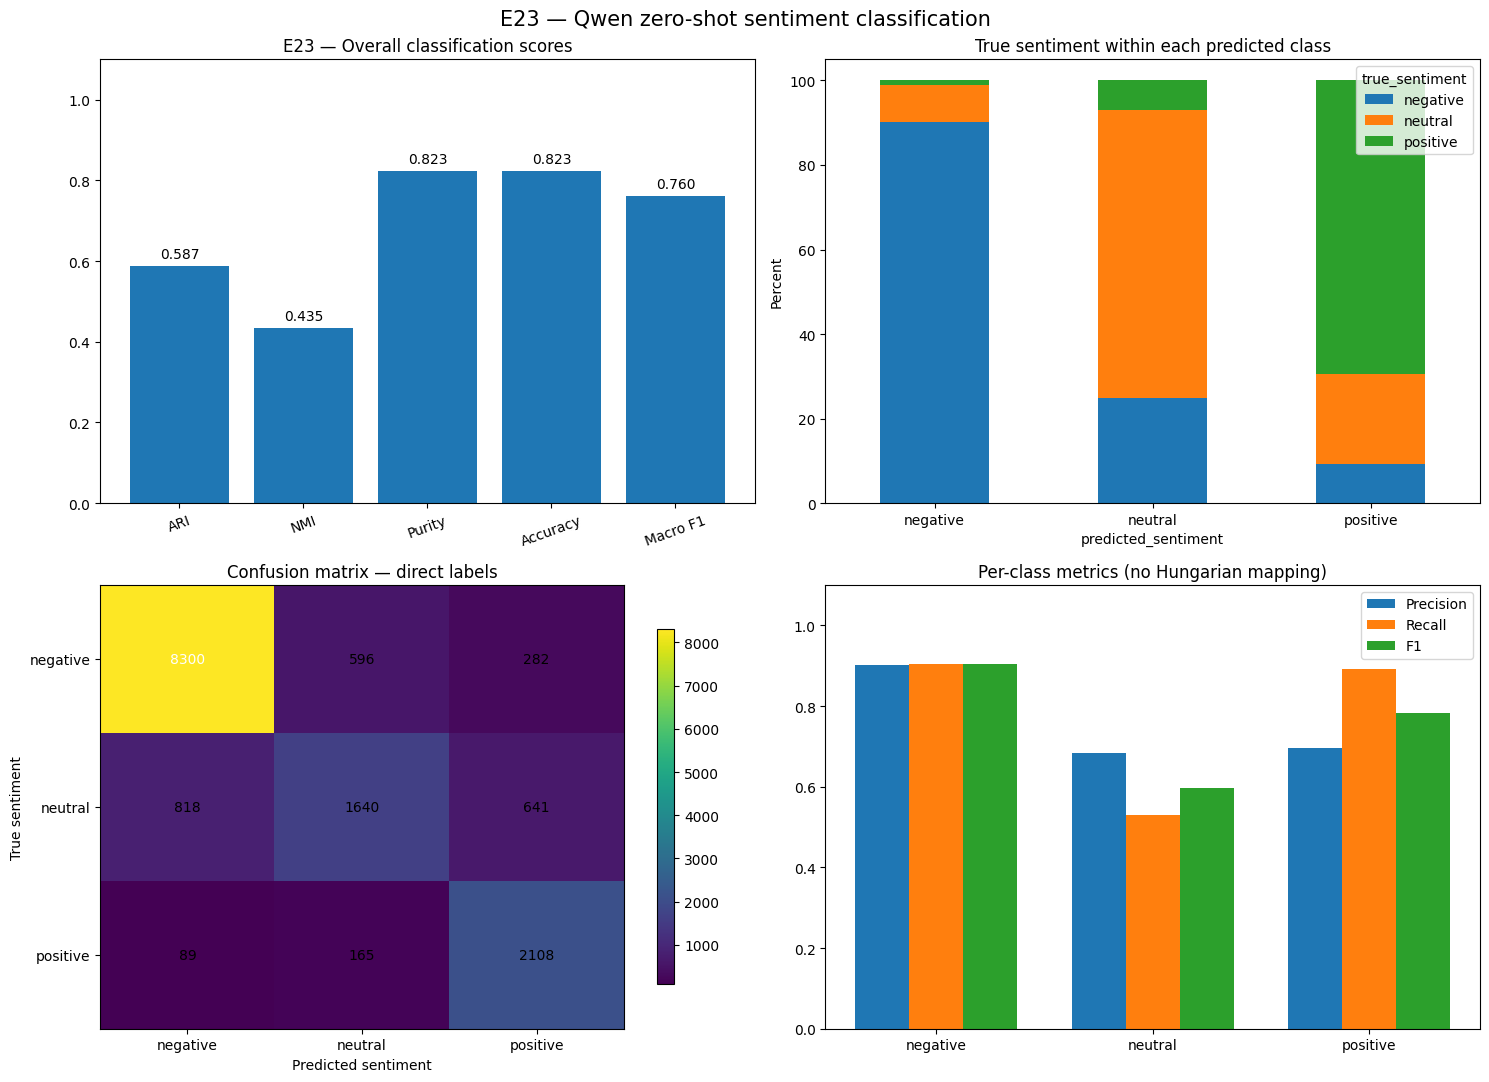

Saved: /content/drive/MyDrive/MSI5001 project/EDA/L6-externaleval/E23/figures/E23_evaluation.png


In [14]:
# 13 — Visualization: direct zero-shot classification (no cluster mapping)
import matplotlib.pyplot as plt
fig,axes=plt.subplots(2,2,figsize=(15,11))
keys=['ARI','NMI','Purity','Accuracy','Macro F1']
vals=[metrics['ari'],metrics['nmi'],metrics['purity'],metrics['accuracy'],metrics['macro_f1']]
axes[0,0].bar(keys,vals); axes[0,0].set_ylim(0,1.1)
axes[0,0].set_title('E23 — Overall classification scores')
axes[0,0].tick_params(axis='x',rotation=20)
for i,v in enumerate(vals): axes[0,0].text(i,v+0.02,f'{v:.3f}',ha='center')
composition.plot(kind='bar',stacked=True,ax=axes[0,1])
axes[0,1].set_title('True sentiment within each predicted class')
axes[0,1].set_ylabel('Percent');axes[0,1].tick_params(axis='x',rotation=0)
mat=CONFUSION.to_numpy()
im=axes[1,0].imshow(mat,aspect='auto',cmap='viridis')
axes[1,0].set_xticks(range(3),CLASSES);axes[1,0].set_yticks(range(3),CLASSES)
axes[1,0].set_xlabel('Predicted sentiment');axes[1,0].set_ylabel('True sentiment')
axes[1,0].set_title('Confusion matrix — direct labels')
for i in range(3):
    for j in range(3): axes[1,0].text(j,i,str(mat[i,j]),ha='center',va='center',color='white' if mat[i,j]>mat.max()/2 else 'black')
fig.colorbar(im,ax=axes[1,0],shrink=.8)
x=np.arange(3);w=.25
axes[1,1].bar(x-w,precision,w,label='Precision');axes[1,1].bar(x,recall,w,label='Recall');axes[1,1].bar(x+w,f1,w,label='F1')
axes[1,1].set_xticks(x,CLASSES);axes[1,1].set_ylim(0,1.1);axes[1,1].legend()
axes[1,1].set_title('Per-class metrics (no Hungarian mapping)')
fig.suptitle('E23 — Qwen zero-shot sentiment classification',fontsize=15)
plt.tight_layout()
fig_dir=OUTPUT_DIR/'figures';fig_dir.mkdir(exist_ok=True,parents=True)
fig.savefig(fig_dir/'E23_evaluation.png',dpi=200,bbox_inches='tight')
plt.show()
print('Saved:',fig_dir/'E23_evaluation.png')